Found 9144 files belonging to 102 classes.
Using 7316 files for training.
Found 9144 files belonging to 102 classes.
Using 1828 files for validation.
Total Classes: 102
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 19s 0us/step



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 102)            │        13,158 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,793,510 (56.43 MB)

 Trainable params: 78,822 (307.90 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/3


c:\study materials\LP-4\solution\.lab\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


229/229 ━━━━━━━━━━━━━━━━━━━━ 311s 1s/step - accuracy: 0.5195 - loss: 2.7485 - val_accuracy: 0.7183 - val_loss: 1.2571
Epoch 2/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 298s 1s/step - accuracy: 0.8078 - loss: 0.7440 - val_accuracy: 0.7910 - val_loss: 0.9398
Epoch 3/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 305s 1s/step - accuracy: 0.9090 - loss: 0.3310 - val_accuracy: 0.8042 - val_loss: 0.8619
58/58 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.8042 - loss: 0.8619
Validation Loss: 0.8619391322135925
Validation Accuracy: 0.804157555103302


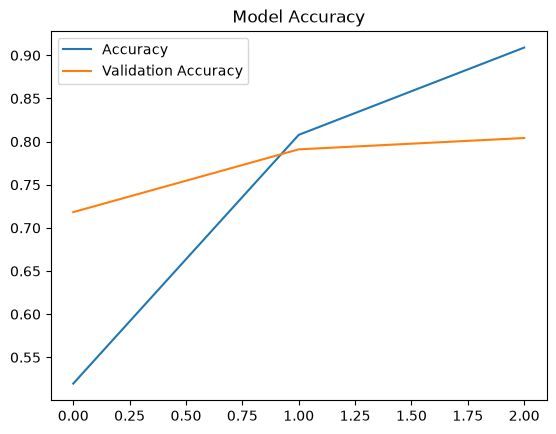

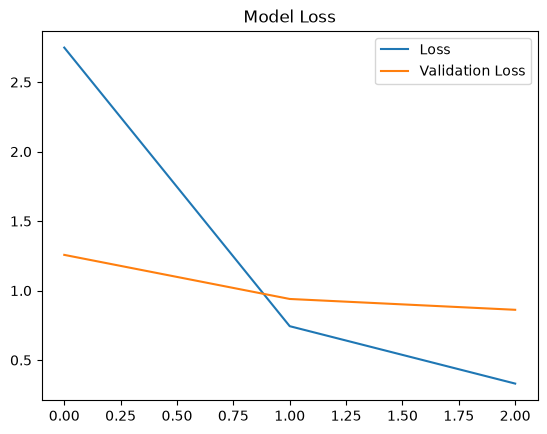

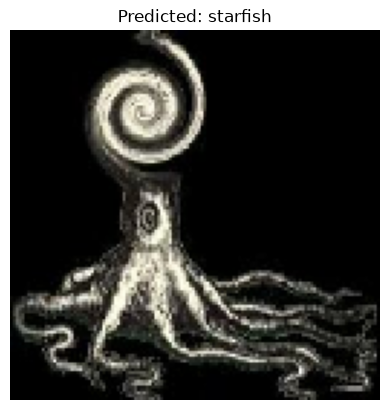

229/229 ━━━━━━━━━━━━━━━━━━━━ 372s 2s/step - accuracy: 0.9636 - loss: 0.1386 - val_accuracy: 0.8271 - val_loss: 0.8717
58/58 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.8271 - loss: 0.8717
Fine-tuned Accuracy: 0.8271334767341614


In [2]:

# Practical 5A: Transfer Learning using VGG16

# 1. Import libraries
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# 2. Load dataset
train = keras.utils.image_dataset_from_directory(
    "caltech-101",
    image_size=(128, 128),
    validation_split=0.2,
    subset="training",
    seed=42
)

val = keras.utils.image_dataset_from_directory(
    "caltech-101",
    image_size=(128, 128),
    validation_split=0.2,
    subset="validation",
    seed=42
)

n_classes = len(train.class_names)
class_names = train.class_names

print("Total Classes:", n_classes)

train = train.prefetch(2)
val = val.prefetch(2)

# 3. Load pre-trained VGG16 model
base = keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze base layers
base.trainable = False

# 4. Build classification model
model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Lambda(keras.applications.vgg16.preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(n_classes, activation="softmax")
])

# 5. Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 6. Train model
history = model.fit(
    train,
    validation_data=val,
    epochs=3
)

# 7. Evaluate model
loss, accuracy = model.evaluate(val)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

# 8. Plot accuracy and loss
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Model Accuracy")
plt.show()

plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Model Loss")
plt.show()

# 9. Visualize prediction
for images, labels in val.take(1):
    prediction = model.predict(images[:1], verbose=0)
    index = prediction[0].argmax()

    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title("Predicted: " + class_names[index])
    plt.axis("off")
    plt.show()

# 10. Fine-tuning (optional)
# Unfreeze the last few VGG16 layers
base.trainable = True

for layer in base.layers[:-4]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train again for fine-tuning
history2 = model.fit(
    train,
    validation_data=val,
    epochs=1
)

# Final evaluation
loss, accuracy = model.evaluate(val)
print("Fine-tuned Accuracy:", accuracy)


# Practical 5A – Object Detection using Transfer Learning with CNN (VGG16)

Problem Statement: Implement Object Detection using Transfer Learning with CNN for the Caltech-101 image classification dataset and VGG / ResNet pre-trained models.

Steps:

1. Set up the environment.
2. Load and preprocess data.
3. Choose a pre-trained model (Transfer Learning).
4. Freeze the base layers and add custom layers for fine-tuning.
5. Train the model.
6. Compute loss.
7. Evaluate the model.
8. Visualize predictions.
9. Fine-tune the model by unfreezing the top layers of the pre-trained model and retraining it.

## 1. First understand the logic

Before understanding the code, let's understand Transfer Learning.

Imagine you want to teach a computer to identify objects such as:

- Airplanes
- Cars
- Dogs
- Flowers
- Motorcycles

Normally, we would train a CNN from scratch using thousands of images.

But training from scratch takes a lot of time and data.

Instead, we use a pre-trained model called VGG16.

VGG16 is already trained on a large dataset called ImageNet. It has already learned to recognize features such as:

- Edges
- Shapes
- Textures
- Patterns
- Object parts

We reuse this knowledge and teach the model to recognize the 101 categories in our Caltech-101 dataset.

This is called Transfer Learning.

[Transfer Learning for Image Classification — (6) Build and Fine-tune the Transfer Learning Model | by Chris Kuo/Dr. Dataman | Medium](https://images.openai.com/static-rsc-4/Ojq2Egq-v4Ne229MVuYoiob0X3Si1rXjZptuBVi27qb8khsL9bxPKWn_n3h5jJw3-0w_IdIhd4Ygc-GbwGhfbvAZE-Z8hvIjb0CeoZ9qjj7QbM02bhLv1LvcN9U_c899qe-BH0x4ou0s2CEsfygvAsT2mGRfzcz_WPZ3_zG-6W0?purpose=inline)

### What exactly are we doing?

Think of the model as two parts:

Part 1: Pre-trained VGG16

## VGG16

Already knows how to extract image features

↓

Part 2: Our custom layers

## Dense layers

Learn to classify images into Caltech-101 categories

↓

Predicted object category

Example: Airplane, Dog, Car

Important clarification: Your code performs image classification, not full object detection. It predicts the category of an image; it does not draw bounding boxes around objects. The practical statement uses "object detection" loosely here.

## 2. Code explanation step by step

### Step 1: Import libraries

```
import matplotlib.pyplot as pltfrom tensorflow import kerasfrom tensorflow.keras import layers
```

- `matplotlib`: Displays images and graphs.
- `keras`: Helps load datasets and build/train deep learning models.
- `layers`: Provides CNN and neural network layers such as Dense and GlobalAveragePooling2D.

### Step 2: Load the dataset

```
train = keras.utils.image_dataset_from_directory(    "caltech-101",    image_size=(128, 128),    validation_split=0.2,    subset="training",    seed=42)
```

This loads images from your local `caltech-101` folder.

Your folder should look approximately like this:

```
caltech-101/
    airplanes/
        image1.jpg
        image2.jpg
    bonsai/
        image1.jpg
    cars/
        image1.jpg
    ...
```

Understand the parameters:

- `"caltech-101"`: Dataset folder path.
- `image_size=(128,128)`: Resizes every image to 128 × 128 pixels.
- `validation_split=0.2`: Keeps 20% of images for validation.
- `subset="training"`: Loads the training portion.
- `seed=42`: Ensures the same random split is used when loading training and validation datasets.

Now the validation dataset:

```
val = keras.utils.image_dataset_from_directory(    "caltech-101",    image_size=(128, 128),    validation_split=0.2,    subset="validation",    seed=42)
```

This loads the remaining 20% of images to evaluate how well the model performs on images it did not train on.

Why do we split the dataset?

- Training data teaches the model.
- Validation data checks how well it performs on unseen images.

### Step 3: Get the number of classes

```
n_classes = len(train.class_names)class_names = train.class_namesprint("Total Classes:", n_classes)
```

- `class_names` stores the names of all image categories.
- `len()` counts the categories.

For example, if the dataset has 101 categories, `n_classes` will be 101.

We need this number to decide how many output neurons our model should have.

### Step 4: Prefetch the dataset

```
train = train.prefetch(2)val = val.prefetch(2)
```

Prefetch prepares upcoming batches while the model is processing the current batch.

This helps improve data-loading performance.

### Step 5: Load the pre-trained VGG16 model

```
base = keras.applications.VGG16(    weights="imagenet",    include_top=False,    input_shape=(128, 128, 3))
```

This is the most important part of Transfer Learning.

Let's understand each parameter:

| Parameter                 | Meaning                                    |
| ------------------------- | ------------------------------------------ |
| `VGG16`                   | Loads the pre-trained VGG16 architecture   |
| `weights="imagenet"`      | Loads weights learned from ImageNet        |
| `include_top=False`       | Removes the original classification layers |
| `input_shape=(128,128,3)` | Accepts 128 × 128 RGB images               |

Why `include_top=False`?

VGG16 was originally trained to classify ImageNet categories.

But our dataset has different categories. So we remove its original classification layers and add our own layers for Caltech-101.

What does `(128,128,3)` mean?

- 128 = Image height.
- 128 = Image width.
- 3 = RGB colour channels (Red, Green, Blue).

### Step 6: Freeze the base layers

```
base.trainable = False
```

This freezes the pre-trained VGG16 layers.

What does freezing mean?

It means we don't allow the original VGG16 weights to change during initial training.

Why?

Because VGG16 has already learned useful image features from ImageNet. We want to reuse that knowledge instead of learning everything again.

### Step 7: Build our classification model

```
model = keras.Sequential([    layers.Input(shape=(128, 128, 3)),    layers.Lambda(keras.applications.vgg16.preprocess_input),    base,    layers.GlobalAveragePooling2D(),    layers.Dense(128, activation="relu"),    layers.Dense(n_classes, activation="softmax")])
```

Let's understand each layer.

1\. Input layer

```
layers.Input(shape=(128, 128, 3))
```

Accepts the input image with dimensions 128 × 128 and 3 colour channels.

2\. Preprocessing layer

```
layers.Lambda(keras.applications.vgg16.preprocess_input)
```

Prepares images in the format expected by VGG16.

VGG16 expects specific pixel preprocessing, so we use its built-in preprocessing function.

3\. VGG16 layer

```
base
```

Extracts useful features from the image using the pre-trained network.

For example, it can recognize edges, shapes, textures and object patterns.

4\. Global Average Pooling

```
layers.GlobalAveragePooling2D()
```

Converts the feature maps produced by VGG16 into a one-dimensional feature vector.

5\. Dense layer

```
layers.Dense(128, activation="relu")
```

Learns patterns from the extracted features.

`128` means this layer has 128 neurons.

`relu` is an activation function that helps the network learn complex patterns.

6\. Output layer

```
layers.Dense(n_classes, activation="softmax")
```

Produces a probability for every category.

For example:

| Category | Probability (example) |
| -------- | --------------------- |
| Airplane | 0.85                  |
| Car      | 0.10                  |
| Dog      | 0.05                  |

The model predicts the category with the highest probability.

`softmax` is used because this is a multi-class classification problem.

### Step 8: Compile the model

```
model.compile(    optimizer="adam",    loss="sparse_categorical_crossentropy",    metrics=["accuracy"])
```

Before training, we configure how the model should learn.

| Parameter                                | Meaning                                                            |
| ---------------------------------------- | ------------------------------------------------------------------ |
| `optimizer="adam"`                       | Updates model weights to reduce errors                             |
| `loss="sparse_categorical_crossentropy"` | Measures prediction error for multiple classes with integer labels |
| `metrics=["accuracy"]`                   | Measures the percentage of correct predictions                     |

What is loss?

Loss measures how far the model's predictions are from the correct answers.

- Lower loss generally means better predictions.
- Higher loss means more prediction error.

What is accuracy?

Accuracy measures how many images the model classifies correctly.

### Step 9: Display model summary

```
model.summary()
```

Displays the model architecture, including:

- Layers.
- Output shapes.
- Number of parameters.
- Trainable and non-trainable parameters.

Because we froze VGG16, its parameters are non-trainable during the first training stage.

### Step 10: Train the model

```
history = model.fit(    train,    validation_data=val,    epochs=3)
```

This is where actual learning happens.

- `train`: Training images.
- `validation_data=val`: Checks performance on validation images after each epoch.
- `epochs=3`: The model goes through the training dataset three times.

During training, the custom Dense layers learn to classify the features extracted by VGG16.

### Step 11: Evaluate the model

```
loss, accuracy = model.evaluate(val)print("Validation Loss:", loss)print("Validation Accuracy:", accuracy)
```

Evaluates the trained model using validation images.

It returns:

- `loss`: Prediction error.
- `accuracy`: Percentage of correctly classified images.

For example, 80% accuracy means the model correctly classified approximately 80 out of every 100 validation images.

### Step 12: Plot accuracy and loss

```
plt.plot(history.history["accuracy"], label="Accuracy")plt.plot(history.history["val_accuracy"], label="Validation Accuracy")plt.legend()plt.title("Model Accuracy")plt.show()
```

This graph displays training accuracy and validation accuracy over the epochs.

```
plt.plot(history.history["loss"], label="Loss")plt.plot(history.history["val_loss"], label="Validation Loss")plt.legend()plt.title("Model Loss")plt.show()
```

This graph displays training loss and validation loss.

Why do we plot these graphs?

To understand how the model learns and whether it is performing well on unseen images.

### Step 13: Visualize prediction

```
for images, labels in val.take(1):    prediction = model.predict(images[:1], verbose=0)    index = prediction[0].argmax()    plt.imshow(images[0].numpy().astype("uint8"))    plt.title("Predicted: " + class_names[index])    plt.axis("off")    plt.show()
```

This displays one validation image and its predicted category.

Understand the logic:

1. `val.take(1)` takes one batch of validation images.
2. `images[:1]` selects the first image from that batch.
3. `model.predict()` predicts its category probabilities.
4. `argmax()` finds the index with the highest probability.
5. `class_names[index]` gets the predicted category name.
6. `imshow()` displays the image.

For example, if the highest probability belongs to the airplane category, the title displays:

`Predicted: airplanes`

Note: Your code displays only the predicted label, not the actual label. It is not drawing a bounding box around the object.

### Step 14: Fine-tune the model

This is the final important concept.

Initially, we froze all VGG16 layers. Now we want to allow some of them to learn from our Caltech-101 images.

```
base.trainable = True
```

This unfreezes the VGG16 model.

But we don't want to train all its layers, so:

```
for layer in base.layers[:-4]:    layer.trainable = False
```

This freezes all layers except the last four layers.

In simple words:

- Earlier: All VGG16 layers were frozen.
- Now: The last four VGG16 layers can learn.
- The custom classification layers can also continue learning.

Why do we fine-tune?

The pre-trained model learned from ImageNet, but our dataset is Caltech-101. Fine-tuning helps it adapt its learned features to our dataset.

Next:

```
model.compile(    optimizer=keras.optimizers.Adam(learning_rate=0.00001),    loss="sparse_categorical_crossentropy",    metrics=["accuracy"])
```

Why use a smaller learning rate?

`0.00001` is a very small learning rate. It helps make small updates to the already-trained VGG16 weights instead of changing them too drastically.

Finally:

```
history2 = model.fit(    train,    validation_data=val,    epochs=1)
```

Trains the model again after unfreezing the last four layers.

```
loss, accuracy = model.evaluate(val)print("Fine-tuned Accuracy:", accuracy)
```

Checks the performance after fine-tuning.

## 3. Understand the complete working

There are two training stages in this practical.

Stage 1 – Transfer Learning

VGG16 frozen

- Load pre-trained VGG16.
- Freeze all its layers.
- Add custom Dense layers.
- Train the custom layers for 3 epochs.

Stage 2 – Fine-tuning

Last 4 VGG16 layers unfrozen

- Unfreeze VGG16.
- Freeze all but its last 4 layers.
- Use a smaller learning rate.
- Train again for 1 epoch.

## 4. Important viva theory questions

Q1. What is Transfer Learning?

Transfer Learning is a technique in which we use a model already trained on a large dataset and reuse its knowledge for a new task.

Q2. What is VGG16?

VGG16 is a pre-trained CNN architecture containing 16 weight layers. It is commonly used for image classification and feature extraction.

Q3. What is ImageNet?

ImageNet is a large image dataset used to train image recognition models.

Q4. What is the Caltech-101 dataset?

It is an image dataset containing images from 101 object categories, such as airplanes, cars, animals and other objects. Some versions also include a background category.

Q5. What is CNN?

CNN stands for Convolutional Neural Network. It is a deep learning model commonly used for image processing and recognition.

Q6. What is freezing a layer?

Freezing means preventing a layer's weights from being updated during training.

Q7. What is fine-tuning?

Fine-tuning means unfreezing some pre-trained layers and training them again on a new dataset.

Q8. What is the difference between feature extraction and fine-tuning?

- Feature extraction: Pre-trained layers remain frozen; only new layers are trained.
- Fine-tuning: Some pre-trained layers are also trained.

Q9. Why do we use `include_top=False`?

It removes the original ImageNet classification layers so that we can add our own classification layers.

Q10. Why do we use GlobalAveragePooling2D?

It converts the feature maps into a one-dimensional vector before passing them to Dense layers.

Q11. Why do we use Softmax?

Softmax converts output values into probabilities for multiple classes.

Q12. What is the purpose of an optimizer?

An optimizer updates the model's weights to reduce the loss.

Q13. Why do we use a small learning rate during fine-tuning?

To make small and careful changes to the pre-trained weights and avoid destroying previously learned features.

Q14. What is the difference between VGG16 and ResNet?

- VGG16 uses a sequence of convolutional layers.
- ResNet uses residual or skip connections to help train deeper networks.

Q15. Is this object detection or image classification?

This implementation performs image classification. Object detection requires identifying object locations using bounding boxes as well as class labels.

## 5. What to explain to the examiner

You can speak this:

"I implemented Transfer Learning using the VGG16 pre-trained CNN model on the Caltech-101 dataset. First, I loaded the images and divided them into training and validation datasets. I resized the images to 128 by 128 pixels.

Then I loaded VGG16 with ImageNet weights and removed its original classification layers. I froze the pre-trained layers and added Global Average Pooling and Dense layers for our 101 image categories.

Next, I compiled and trained the model using Adam optimizer and sparse categorical crossentropy loss. I evaluated the model using validation accuracy and loss, plotted the graphs and visualized a prediction.

Finally, I performed fine-tuning by unfreezing the last four VGG16 layers and training again using a smaller learning rate."

## 6. Quick revision

| Concept                | Remember                          |
| ---------------------- | --------------------------------- |
| Transfer Learning      | Reuse a pre-trained model         |
| VGG16                  | Pre-trained CNN                   |
| ImageNet               | Dataset used for pre-training     |
| `include_top=False`    | Removes original output layers    |
| `base.trainable=False` | Freezes VGG16                     |
| GlobalAveragePooling2D | Reduces feature maps              |
| Dense                  | Fully connected layer             |
| Softmax                | Multi-class probabilities         |
| Loss                   | Measures prediction error         |
| Accuracy               | Measures correct predictions      |
| Fine-tuning            | Train selected pre-trained layers |
| Learning rate          | Controls size of weight updates   |

Important practical notes:

1. Your `caltech-101` folder must contain subfolders for each class, with images inside them.
2. VGG16's ImageNet weights may need to download the first time you run the code. An internet connection is required unless those weights are already cached.
3. The exact number of classes is determined by `train.class_names`; check the printed value rather than assuming it is exactly 101.
4. Three initial epochs and one fine-tuning epoch are suitable for a basic practical demonstration, but may not produce the best accuracy.

The three things you must understand for this practical: Transfer Learning means reusing VGG16, freezing means keeping its learned weights unchanged, and fine-tuning means allowing selected VGG16 layers to learn from your dataset.